# OLCFourStages - Test on the 3 x 3 Grid

`olc_four_stages` on the 3x3 grid graph with B = 3 buses.

In [1]:
%config InlineBackend.figure_format = "retina"

import importlib.util
import sys, os

sys.path.insert(0, os.path.abspath(".."))

missing = [name for name in ("networkx", "matplotlib", "gurobipy")
           if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f"missing packages: {', '.join(missing)}. See the README of the repository.")
if importlib.util.find_spec("LineCover") is None:
    raise ImportError("LineCover not found. Run this notebook from the notebooks folder of the repository.")

import random
import gurobipy as gp
from LineCover import *
from LineCover.SystemKit.network import Network
from LineCover.Metaheuristics import olc_four_stages, STAGES
from LineCover.Metaheuristics.olc_four_stages import _phase_harmonisation

print("Gurobi", gp.gurobi.version())

Gurobi (13, 0, 1)


In [2]:
SEED = 0

S = 20
LS_L_MAX = 5
PERT_L_MAX = 5
MAX_EVALUATIONS = 100_000
PH_RESTARTS = 250
PH_MAX_HOPS = 10**6 

# The figures are written into this folder, overwriting files of the same name.
FIGURE_DIR = "OLCFourStages_Test_3x3_Grid/figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

edge_list, pos = get_grid_graph_data(3, 3)
network = Network(edge_list, pos=pos, seed=SEED)
G = network.graph

In [3]:
def plot_buses(system, name):
    for bid, bus in sorted(system.buses.items()):
        print(f"b_{bid}: P_b = {bus.P_b}, t_b = {bus.t_b:.4f}")
        network.visualize_bus(
            bus,
            filename=os.path.join(FIGURE_DIR, f"{name}_bus{bid}.pdf"),
            caption="",
        )


def run(B):
    result = olc_four_stages(
        G, B,
        max_evaluations=MAX_EVALUATIONS, s=S,
        ph_restarts=PH_RESTARTS, ph_max_hops=PH_MAX_HOPS,
        ls_L_max=LS_L_MAX, pert_L_max=PERT_L_MAX,
        seed=SEED,
    )
    print(f"--- B = {B} ---")
    for stage in STAGES:
        print(f"{stage:<24} EA = {result.values[stage]:.4f}")
    return result

Set parameter Username
Set parameter LicenseID to value 2771095
Academic license - for non-commercial use only - expires 2027-01-28
--- B = 3 ---
initial_solution         EA = 7.1653
phase_harmonisation_1    EA = 7.1636
route_ils                EA = 5.5420
phase_harmonisation_2    EA = 5.5384
--- initial solution after phase harmonisation ---
b_1: P_b = 10, t_b = 1.0000


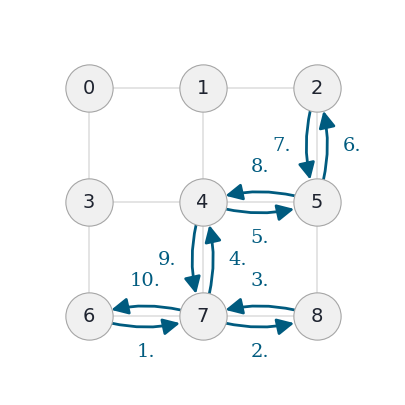

b_2: P_b = 10, t_b = 0.3045


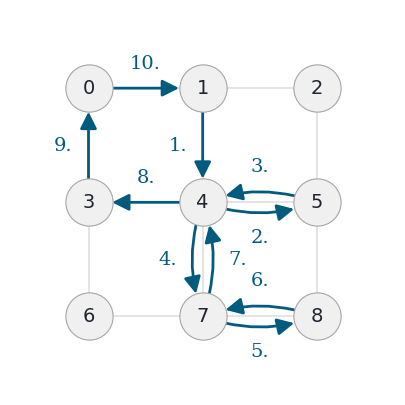

b_3: P_b = 8, t_b = 0.1979


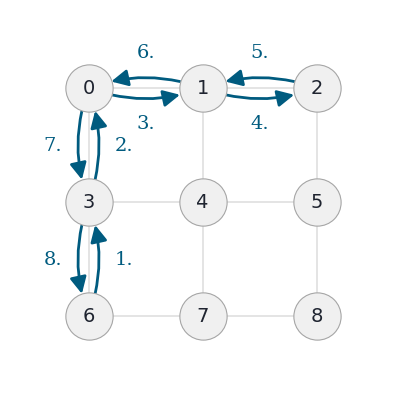

--- final solution ---
b_1: P_b = 8, t_b = 0.1992


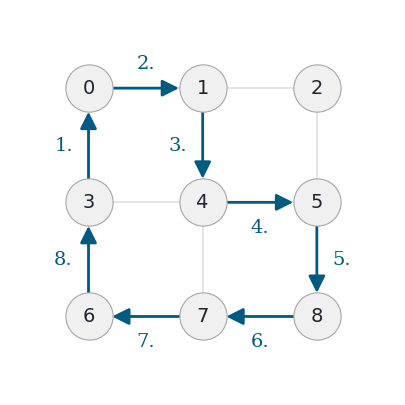

b_2: P_b = 8, t_b = 0.5283


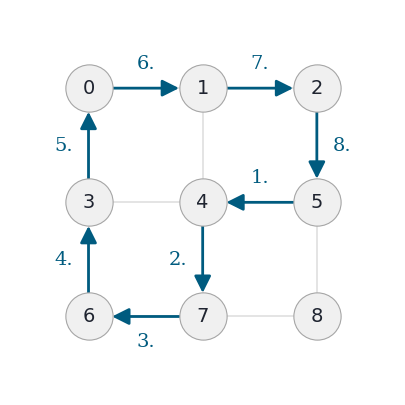

b_3: P_b = 8, t_b = 0.9175


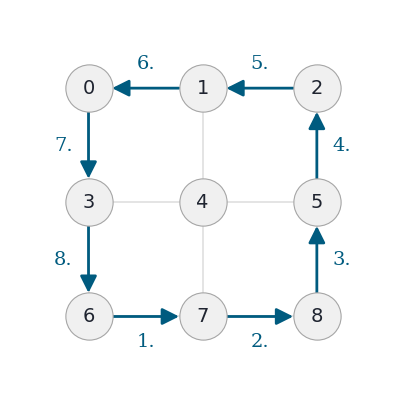

In [4]:
B = 3

random.seed(SEED)
buses, _ = build_initial_solution(G, B)
initial = BusSystem(buses=buses, V=set(G.nodes()))
initial.init_pair_means()
initial, initial_value = _phase_harmonisation(
    initial, float(initial.ensemble_average()), PH_RESTARTS, PH_MAX_HOPS)

result = run(B)

print("--- initial solution after phase harmonisation ---")
plot_buses(initial, "B3_initial")
print("--- final solution ---")
plot_buses(result.system, "B3_final")